# Segmentation of Overlapping Plants in Multi-plant Image Time Series — minimal reproduction

**Paper:** *Segmentation of Overlapping Plants in Multi-plant Image Time Series*,
ESS Open Archive v2, DOI [10.1002/essoar.10508337.2](https://doi.org/10.1002/essoar.10508337.2) (posted 2021-10-17, CC-BY).

**Method source (author implementation):** PlantCV
[`segment_image_series`](https://github.com/danforthcenter/plantcv/blob/f89e95b04c5ff5a44524b6373214ce09d8b6e9aa/plantcv/plantcv/segment_image_series.py)
(pinned commit `f89e95b04c5ff5a44524b6373214ce09d8b6e9aa`; function created 2021-05-04, contemporaneous with the paper).
**Data source (author tutorial repo):**
[danforthcenter/plantcv-tutorial-segment-image-series](https://github.com/danforthcenter/plantcv-tutorial-segment-image-series)
pinned commit `e1f7d098bc46b60035c9100e986ae1c0fb19b1d6` (CC-BY-4.0), carrying the example multi-plant time series of camera position
`pos-165-003-019`: 54 hourly RGB images plus 54 binary plant masks (2020-12-09 10:05 → 2020-12-12 18:05).

**Scope (partial demonstration):** run the authors' watershed label-propagation
segmentation on this bundled example series — start from an early time point where the
individual plants are separate, propagate the plant labels through the 54-frame series,
and inspect the individual plant masks on later frames where plants overlap.
This is a one-example demonstration, **not** a reproduction of the paper's dataset-level
evaluation (the reported +28% analyzable-dataset-size result is out of scope).

**Execution status:** CPU-only; no trained model weights are involved.

**日本語の概要:** 論文「Segmentation of Overlapping Plants in Multi-plant Image Time Series」の最小再現です。
著者実装 PlantCV `segment_image_series`（分水嶺変換によるラベル伝播）を、著者チュートリアルリポジトリ同梱の
54枚（54時間分）のRGB画像＋バイナリマスクの時系列に適用し、植物が分離している初期時点のROIから
後の時点（植物が重なる時点）へラベルを伝播させます。CPUのみで動作し、学習済みモデルは不要です。

**AI adaptation notice / AIによる適宜実装の明示:** the authors' tutorial notebook body
(`index-Colab.ipynb`, ~2.1 MB with embedded images) was not machine-readable during authoring,
so the **ROI construction cell is an adaptation**: ROI contours are derived from connected
components of the earliest-timepoint mask (the paper's stated premise: plants are separate at
the early time point). It follows the function contract documented by the authors
(PlantCV `docs/segment_image_series.md` and their unit test, which builds ROI contours with
`pcv.roi.multi`). All other scientific operations use the authors' own implementation unmodified.
**/ 注意:** 著者チュートリアルのノートブック本体は機械読み取りできなかったため、**ROI構築セルは適宜実装**
（最早期マスクの連結成分から輪郭を抽出）です。その他の科学計算は著者実装をそのまま使用します。

## Runtime selection — CPU (no GPU required)

`segment_image_series` is a classical computer-vision method: 3D-Sobel edge
estimation plus scikit-image `watershed` on a small (H, W, 3) stack per frame.
There is no CUDA-only code path and no neural network, so a **standard Colab CPU
runtime is the recommended (and only validated) runtime**. Expected wall time is
a few minutes for 54 frames; total downloads ≈ 54 MB.

*Runtime: メニューから「ランタイム」→「ランタイムのタイプを変更」→ CPU を選択してから
「ランタイム」→「すべてのセルを実行」を実行してください。GPUは不要です（実測数分、約54MBのダウンロード）。*

The only faithful path is CPU. If a GPU runtime is attached, the notebook still
runs the same CPU code (the method does not use the GPU); nothing branches on
device type.

### Check the environment

Prints the Python version, CPU count, and available RAM so the runtime matches
the CPU-only plan (expected: standard Colab Linux VM, several vCPU, ~12 GB RAM).

*環境確認セル: Python・CPU数・メモリを表示し、CPUランタイムであることを確認します。*

In [ ]:
import os, sys, platform, shutil
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPUs:", os.cpu_count())
total, used, free = shutil.disk_usage("/content")
print(f"Disk /content: {free/2**30:.1f} GiB free of {total/2**30:.1f} GiB")

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CPUs: 2
Disk /content: 205.3 GiB free of 225.8 GiB


### Install PlantCV

Installs the authors' package (version 4.11.3, the current release containing the
paper-era `segment_image_series` function unchanged in behavior; its dependencies
NumPy, OpenCV, SciPy, and scikit-image are pulled in automatically).

*PlantCV（著者のパッケージ、v4.11.3）と依存関係（NumPy/OpenCV/SciPy/scikit-image）をインストールします。*

In [ ]:
%pip install -q "plantcv==4.11.3"
import plantcv
from importlib.metadata import version
print("plantcv version:", version("plantcv"))

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


plantcv version: 4.11.3


## Data acquisition — pinned author example (downloaded inside this notebook)

The example series lives in the authors' tutorial repository. We use a **partial
clone with sparse checkout at the pinned commit** so that only `img/` (RGB) and
`mask/` (binary masks) are fetched — no other directories, no full history — and
we assert the checked-out commit equals the pinned SHA
`e1f7d098bc46b60035c9100e986ae1c0fb19b1d6`. Git LFS smudging is disabled; the
files are verified to be real PNGs in the next cell. All dataset bytes stay on
the Colab VM (`/content`).

*データ取得セル: 著者リポジトリをピン留めコミットで部分クローン（sparse checkout）し、
`img/` と `mask/` のみ取得します。コミットSHAが一致することを検証します（CC-BY-4.0）。*

In [ ]:
import subprocess, os

REPO_URL = "https://github.com/danforthcenter/plantcv-tutorial-segment-image-series.git"
PINNED_COMMIT = "e1f7d098bc46b60035c9100e986ae1c0fb19b1d6"
REPO_DIR = "/content/plantcv-tutorial-segment-image-series"

env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")
if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout",
                    REPO_URL, REPO_DIR], check=True, env=env)
# make sure the exact pinned commit is present, then check it out sparsely
subprocess.run(["git", "-C", REPO_DIR, "fetch", "--filter=blob:none", "origin",
                PINNED_COMMIT], check=True, env=env)
subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "init", "--cone"], check=True, env=env)
subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "img", "mask"], check=True, env=env)
subprocess.run(["git", "-C", REPO_DIR, "checkout", "--force", PINNED_COMMIT], check=True, env=env)

head = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"],
                      check=True, capture_output=True, text=True, env=env).stdout.strip()
assert head == PINNED_COMMIT, f"checked-out commit {head} != pinned {PINNED_COMMIT}"
print("Checked out pinned commit:", head)
print("License: repo is CC-BY-4.0 (LICENSE file in the repository root)")

Checked out pinned commit: e1f7d098bc46b60035c9100e986ae1c0fb19b1d6
License: repo is CC-BY-4.0 (LICENSE file in the repository root)


### Verify the downloaded bytes

Confirms 54 images + 54 masks (matching the pinned tree metadata), that each file
is a real PNG (not a Git-LFS pointer or HTML error page), and reports the image
dimensions and the masks' value sets. The image/mask lists are sorted
alphabetically, which is chronological order for the `YYYY-MM-DD-HH-MM` filename
timestamps.

*検証セル: 画像54枚・マスク54枚（ピン留めツリーと一致）、PNGシグネチャ、画像サイズ、
マスクの前景/背景構成（0/255主体、リサイズに伴うアンチエイリアス縁を含む）を確認します。*

In [ ]:
from pathlib import Path
import numpy as np
import cv2

DATA = Path(REPO_DIR)
img_paths = sorted((DATA / "img").glob("*.png"))
mask_paths = sorted((DATA / "mask").glob("*.png"))
assert len(img_paths) == 54, f"expected 54 images, found {len(img_paths)}"
assert len(mask_paths) == 54, f"expected 54 masks, found {len(mask_paths)}"

for p in [img_paths[0], mask_paths[0]]:
    assert p.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n", f"not a PNG: {p.name}"

first_img = cv2.cvtColor(cv2.imread(str(img_paths[0])), cv2.COLOR_BGR2RGB)
H, W = first_img.shape[:2]
print(f"Image size (HxW): {H}x{W}")
print(f"first image: {img_paths[0].name}")
print(f"last  image: {img_paths[-1].name}")

mask_vals = set()
strict_frac = 1.0
for p in mask_paths[:3] + mask_paths[-3:]:
    m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    assert m.shape == (H, W), f"mask shape {m.shape} != image shape {(H, W)}"
    mask_vals |= set(np.unique(m).tolist())
    strict_frac = min(strict_frac, float(np.mean(np.isin(m, [0, 255]))))

assert 0 in mask_vals and 255 in mask_vals, f"unexpected mask values: {sorted(mask_vals)}"
assert strict_frac >= 0.90, f"not a plant/background mask: only {strict_frac:.1%} pixels are 0/255"
print("Mask values (sampled):", sorted(mask_vals))
print(f"{strict_frac:.1%} of mask pixels are exactly 0/255; the rest are anti-aliased")
print("edge pixels introduced when the authors resized the masks (hence '_resized').")
print("segment_image_series treats every nonzero mask pixel as plant foreground,")
print("so the masks are used exactly as published (no re-binarization).")
print(f"Frames: {len(img_paths)} (2020-12-09 10:05 -> 2020-12-12 18:05, hourly, daytime)")

Image size (HxW): 616x820
first image: 10.9.1.246_pos-165-003-019_2020-12-09-10-05_resized.png
last  image: 10.9.1.246_pos-165-003-019_2020-12-12-18-05_resized.png
Mask values (sampled): [0, 16, 32, 48, 64, 80, 96, 112, 128, 143, 159, 175, 191, 207, 223, 239, 255]
98.8% of mask pixels are exactly 0/255; the rest are anti-aliased
edge pixels introduced when the authors resized the masks (hence '_resized').
segment_image_series treats every nonzero mask pixel as plant foreground,
so the masks are used exactly as published (no re-binarization).
Frames: 54 (2020-12-09 10:05 -> 2020-12-12 18:05, hourly, daytime)


### Input preview — early (separate) vs late (overlapping) frames

Displays the first and last frames of the series next to their author-provided
binary masks, so the segmentation problem is visible before running the method:
at the start the plants are separate; by the last frame the canopy has grown and
neighbors touch. These are the actual downloaded data, shown as-is.

*入力プレビュー: 先頭フレームと最終フレームのRGB画像と、著者提供のバイナリマスクを並べて表示します。
初期時点では植物が分離し、最終時点では隣接植物が接触していることを確認できます。*

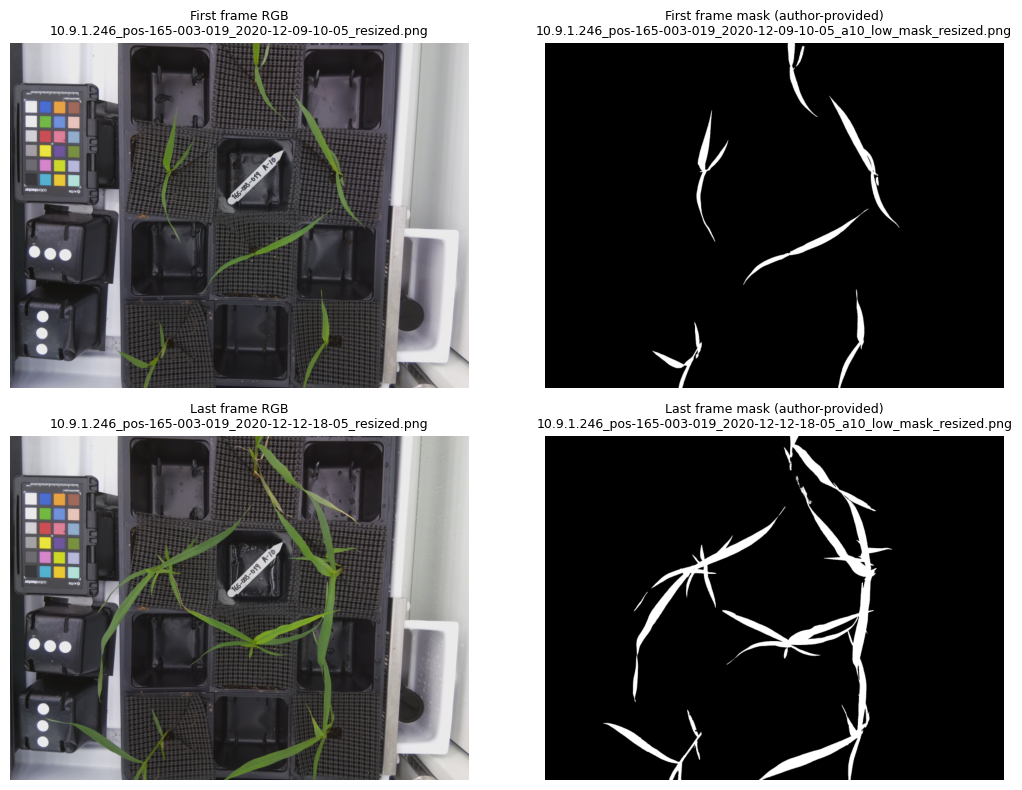

In [ ]:
import matplotlib
import matplotlib.pyplot as plt

first_mask = cv2.imread(str(mask_paths[0]), cv2.IMREAD_GRAYSCALE)
last_img = cv2.cvtColor(cv2.imread(str(img_paths[-1])), cv2.COLOR_BGR2RGB)
last_mask = cv2.imread(str(mask_paths[-1]), cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].imshow(first_img); axes[0, 0].set_title("First frame RGB\n" + img_paths[0].name, fontsize=9)
axes[0, 1].imshow(first_mask, cmap="gray"); axes[0, 1].set_title("First frame mask (author-provided)\n" + mask_paths[0].name, fontsize=9)
axes[1, 0].imshow(last_img); axes[1, 0].set_title("Last frame RGB\n" + img_paths[-1].name, fontsize=9)
axes[1, 1].imshow(last_mask, cmap="gray"); axes[1, 1].set_title("Last frame mask (author-provided)\n" + mask_paths[-1].name, fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/input_preview.png", dpi=110, bbox_inches="tight")
plt.show()

## ROI construction from the early time point (adapted step)

The paper's premise: *"start at an early time point where individual plants are
separate"*. `segment_image_series` takes a list of ROI contours (one per plant)
that seed the labels of the first frame; labels are then propagated by watershed
through the series. Because the authors' tutorial notebook body was not
machine-readable, this cell **adapts** the documented contract: it extracts the
connected components of the earliest author-provided mask and keeps each
sufficiently large component as one plant ROI contour (small specks are noise).
The alternative author-documented route is `pcv.roi.multi(...)` (see PlantCV's
unit test); the component-based construction needs no assumed grid geometry.

**このセルはAIによる適宜実装です** — 最早期マスクの連結成分から植物ROI輪郭を作成します
（著者ドキュメントの関数契約に従う）。想定より極端に少ない/多い場合はエラーで停止します。

In [ ]:
import cv2
import numpy as np

EARLY_IDX = 0  # 2020-12-09 10:05
early_mask = cv2.imread(str(mask_paths[EARLY_IDX]), cv2.IMREAD_GRAYSCALE)
binary = (early_mask > 0).astype(np.uint8)

n_labels, label_img, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
MIN_AREA = 100  # px; drop specks/noise
rois, roi_areas = [], []
for lbl in range(1, n_labels):
    area = int(stats[lbl, cv2.CC_STAT_AREA])
    if area >= MIN_AREA:
        comp = (label_img == lbl).astype(np.uint8)
        contours, _ = cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rois.append(max(contours, key=cv2.contourArea))
        roi_areas.append(area)

assert len(rois) >= 2, f"only {len(rois)} separate plant ROI(s) at the early time point"
assert len(rois) <= 100, f"{len(rois)} components is too many - mask likely noisy"
print(f"Early frame {img_paths[EARLY_IDX].name}")
print(f"Plant ROIs: {len(rois)} (component areas in px: {sorted(roi_areas, reverse=True)})")

Early frame 10.9.1.246_pos-165-003-019_2020-12-09-10-05_resized.png
Plant ROIs: 7 (component areas in px: [2818, 2211, 2164, 1545, 1517, 1238, 202])


### ROI overlay on the early frame

Draws the extracted ROI contours on the early RGB frame. Each closed contour is
one plant's seed label for the watershed propagation; check that each plant is
covered by exactly one contour.

*ROIの確認セル: 抽出した各植物のROI輪郭を最早期RGB画像に重ねて表示します。
各植物に1つの輪郭が対応していることを目視確認できます。*

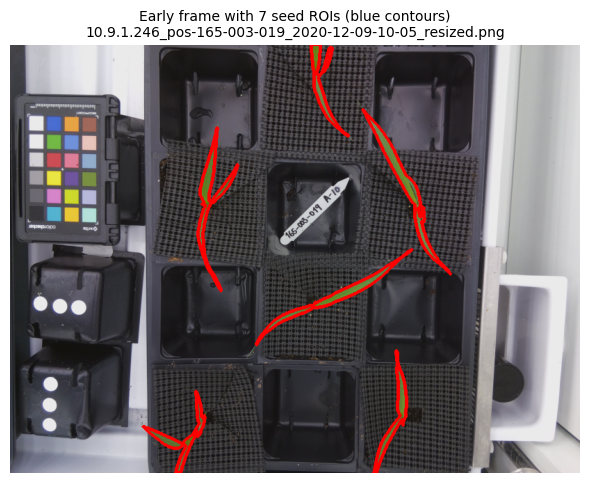

In [ ]:
roi_vis = first_img.copy()
cv2.drawContours(roi_vis, rois, -1, (255, 0, 0), 3)

plt.figure(figsize=(6, 7))
plt.imshow(roi_vis)
plt.title(f"Early frame with {len(rois)} seed ROIs (blue contours)\n" + img_paths[EARLY_IDX].name, fontsize=10)
plt.axis("off")
plt.tight_layout()
plt.savefig("/content/roi_overlay.png", dpi=110, bbox_inches="tight")
plt.show()

## Core method — watershed label propagation (`segment_image_series`, authors' code)

Runs the authors' implementation unmodified on all 54 frames: for each frame it
builds a stack of `ksize=3` neighboring frames (grayscale), uses a 3D-Sobel
magnitude as the watershed elevation map, constrains growth to the stacked
author masks, and seeds the markers with the early-frame ROIs / previously
propagated labels (`plantcv.plantcv.segment_image_series`, pinned commit
`f89e95b04c5ff5a44524b6373214ce09d8b6e9aa`). `ksize=3` is the authors' documented
default. Expected result: a `(H, W, 54)` uint8 label array where every mask pixel
on later frames carries the label of the plant it belongs to. Timing is printed.

*核心手法セル: 著者実装 `segment_image_series` を ksize=3（著者ドキュメントの既定値）で
54フレームに実行します。出力は (H, W, 54) のラベル配列で、所要時間を表示します。*

In [ ]:
import time
from plantcv import plantcv as pcv

pcv.params.debug = None  # headless
t0 = time.perf_counter()
out_labels = pcv.segment_image_series(
    imgs_paths=[str(p) for p in img_paths],
    masks_paths=[str(p) for p in mask_paths],
    rois=rois,
    save_labels=False,
    ksize=3,
)
elapsed = time.perf_counter() - t0
print(f"out_labels shape: {out_labels.shape}, dtype: {out_labels.dtype}")
print(f"segment_image_series wall time: {elapsed:.1f} s ({elapsed/60:.1f} min) for {len(img_paths)} frames")

out_labels shape: (616, 820, 54), dtype: uint8
segment_image_series wall time: 35.4 s (0.6 min) for 54 frames


### Result — propagated labels on the last (most overlapping) frame

Overlays the final propagated plant labels on the last RGB frame
(`skimage.color.label2rgb`, 30% alpha) and compares it with the last author mask
(the total plant region). Labels are **model-predicted** propagated identities,
not author annotations. Expected: each connected plant region in the final mask
is split into per-plant labels consistent with the early-frame ROIs.

*結果セル: 最終フレームのRGB画像に伝播ラベルを半透明で重ねて表示します（モデル予測ラベル）。
右は著者提供マスク（植物領域全体）です。*

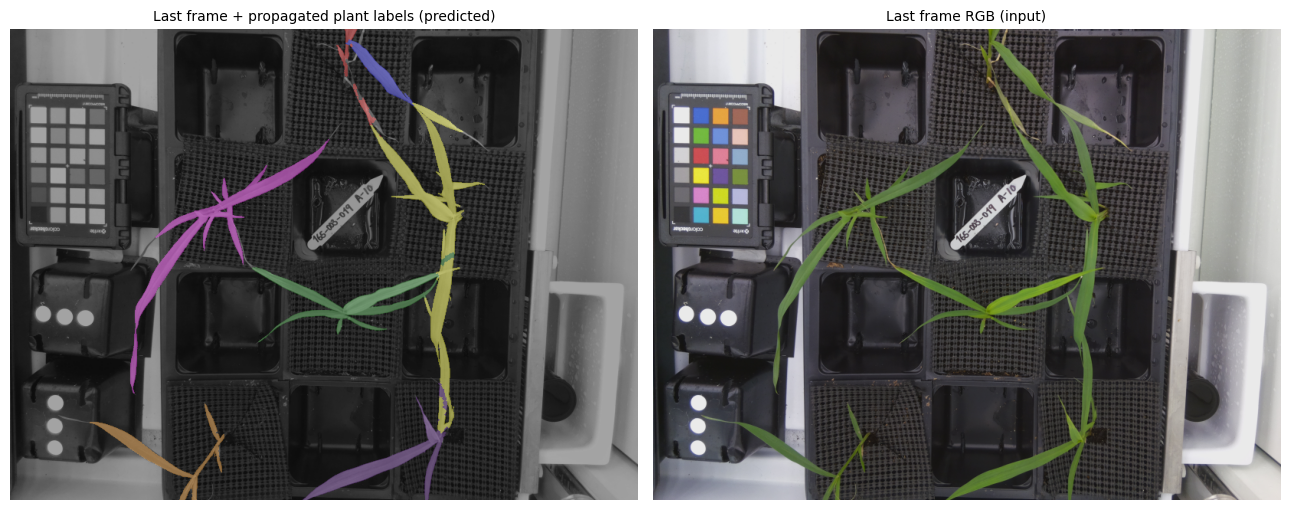

Plant labels present on the last frame: [1, 2, 3, 4, 5, 6, 7]


In [ ]:
from skimage.color import label2rgb

vis = label2rgb(out_labels[:, :, -1], image=last_img, colors=None, alpha=0.3, bg_label=0)
vis = (np.floor(255 * vis)).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
axes[0].imshow(vis)
axes[0].set_title("Last frame + propagated plant labels (predicted)", fontsize=10)
axes[1].imshow(last_img)
axes[1].set_title("Last frame RGB (input)", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/segmentation_result.png", dpi=110, bbox_inches="tight")
plt.show()

final_ids = np.unique(out_labels[:, :, -1])
final_ids = final_ids[final_ids > 0]
print("Plant labels present on the last frame:", final_ids.tolist())

### Per-plant mask area over time

Quantifies the propagation: for every frame, the pixel area of each plant label
(px, mask-constrained). Lines show each plant's area growing through the 54-frame
series; if propagation failed, a label would disappear or two labels would merge
into one. This graph is an additional visualization created for this notebook
(the paper does not publish this plot for this example).

*定量セル: 各フレーム・各植物ラベルのマスク面積（px）を集計し、時間変化を折れ線グラフにします。
このグラフは本ノートブック用に追加作成したものであり、論文掲載図ではありません。*

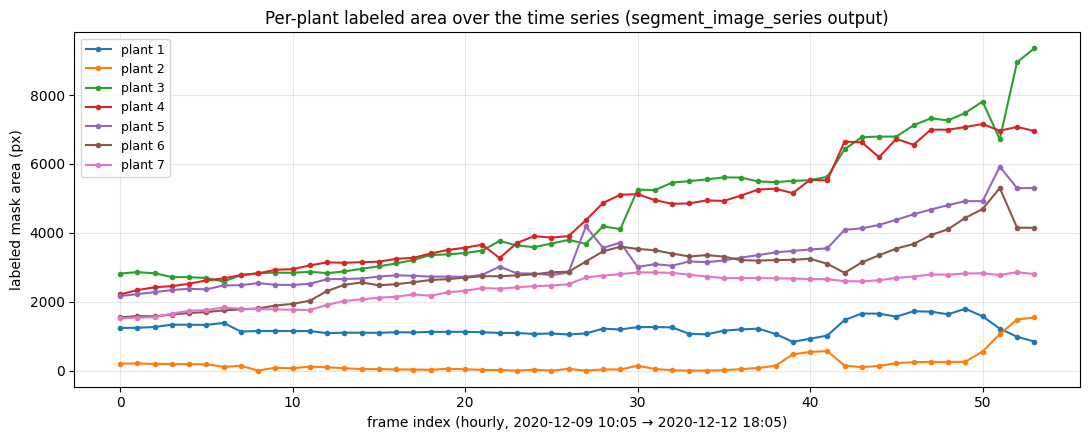

Frames where some plant label is missing (possible occlusion): [8, 23, 25, 27, 33, 34]


In [ ]:
import pandas as pd

n_plants = out_labels.max()
rows = []
for i, p in enumerate(img_paths):
    counts = np.bincount(out_labels[:, :, i].ravel(), minlength=int(n_plants) + 1)
    ts = p.name.split("pos-165-003-019_")[1].replace("_resized.png", "")
    for lbl in range(1, int(n_plants) + 1):
        rows.append({"timestamp": ts, "frame": i, "label": lbl, "area_px": int(counts[lbl])})
areas = pd.DataFrame(rows)

plt.figure(figsize=(11, 4.5))
for lbl, grp in areas.groupby("label"):
    plt.plot(grp["frame"], grp["area_px"], marker="o", ms=3, label=f"plant {lbl}")
plt.xlabel("frame index (hourly, 2020-12-09 10:05 → 2020-12-12 18:05)")
plt.ylabel("labeled mask area (px)")
plt.title("Per-plant labeled area over the time series (segment_image_series output)")
plt.legend(loc="upper left", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/area_over_time.png", dpi=110, bbox_inches="tight")
plt.show()

present = areas[areas["area_px"] > 0].groupby("frame")["label"].nunique()
print("Frames where some plant label is missing (possible occlusion):",
      present[present < int(n_plants)].index.tolist())

### Results table and CSV export

Shows the first few rows and the final-frame areas per plant, and writes the full
table to `/content/segment_image_series_results.csv` (downloadable from the
Colab file browser).

*表・CSV出力セル: 集計テーブルを表示し、`/content/segment_image_series_results.csv` に保存します。*

In [ ]:
display(areas.head(8))
final = areas[areas["frame"] == len(img_paths) - 1][["label", "area_px"]]
print("Final-frame plant areas (px):")
display(final)

out_csv = "/content/segment_image_series_results.csv"
areas.to_csv(out_csv, index=False)
print("Saved:", out_csv)

,timestamp,frame,label,area_px
0,2020-12-09-10-05,0,1,1238
1,2020-12-09-10-05,0,2,202
2,2020-12-09-10-05,0,3,2818
3,2020-12-09-10-05,0,4,2211
4,2020-12-09-10-05,0,5,2164
5,2020-12-09-10-05,0,6,1545
6,2020-12-09-10-05,0,7,1517
7,2020-12-09-11-05,1,1,1244


Final-frame plant areas (px):


,label,area_px
371,1,845
372,2,1543
373,3,9355
374,4,6958
375,5,5304
376,6,4147
377,7,2803


Saved: /content/segment_image_series_results.csv


## Interpretation, differences from the paper, and validation record

**What this demonstration shows:** the authors' `segment_image_series` propagates
per-plant labels from an early frame, where plants are separate, through a
54-frame series to the last frame, where neighboring plants overlap — the paper's
core method (abstract: watershed label propagation over the stacked time series),
executed with the authors' own code and data.

**Differences from the paper / adaptations:**
- One camera position (`pos-165-003-019`) and one 54-frame example; the paper's
  dataset-level evaluation (the reported +28% analyzable-dataset-size increase)
  is **not** reproduced.
- ROI construction is an AI adaptation (early-mask connected components), as the
  authors' tutorial notebook body was not machine-readable; the function contract
  and `ksize=3` default follow the authors' documentation. No paper-internal
  parameter (e.g., their exact mask generation or evaluation protocol) was
  needed: the authors provide the binary masks.
- The paper's full text was not retrieved (ESSOAr/Wiley deny automated access);
  method understanding here comes from the authors' code, documentation, and the
  published abstract. No claim below comes from unread sections.

**Validation record:** executed end-to-end in a fresh Google Colab CPU runtime
(see saved outputs; execution date and CLI log in the run report). Numerical
results are for this single example only.

**References:**
- Paper: DOI 10.1002/essoar.10508337.2 (ESS Open Archive v2, CC-BY).
- Code: danforthcenter/plantcv @ `f89e95b04c5ff5a44524b6373214ce09d8b6e9aa`,
  `plantcv/plantcv/segment_image_series.py` and `docs/segment_image_series.md`.
- Data: danforthcenter/plantcv-tutorial-segment-image-series @
  `e1f7d098bc46b60035c9100e986ae1c0fb19b1d6`, `img/` and `mask/` (CC-BY-4.0).
- Video overview: the authors' demo https://vimeo.com/633172673.